# Student Performance Prediction Using Linear Regression

## Project Overview

This project uses student grade data to estimate the final grade (`G3`) from earlier grade information.

The work begins with a **single-feature linear regression model** that uses `G2` to predict `G3`. It then extends the model to use two features, `G1` and `G2`, and compares the two approaches using validation Mean Absolute Error (MAE).

The linear regression model is implemented manually with **NumPy**. The notebook builds the prediction function, cost function, gradient calculations and gradient descent algorithm. Scikit-learn is used only for `train_test_split`, which divides the data into training, validation and test sets; it is not used to train the regression model.

The final section uses the selected trained model to make a prediction for a new `G2` value.

## 1. Import the required libraries

In [ ]:
# Import our libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load and inspect the dataset

In [ ]:
# Lets read our data
data = pd.read_csv("data/student-mat.csv", sep = ";")

The dataset is loaded from `data/student-mat.csv`. The file is read with a semicolon (`;`) separator.

The next cell checks the dataset dimensions. The notebook reports **395 rows and 33 columns**.

In [ ]:
data.shape

(395, 33)

### Select the input feature and target

In [ ]:
# lets select our variable G2 and target G3

X = data["G2"].to_numpy(dtype=float)
y = data["G3"].to_numpy(dtype=float)

# Inspecting the first 5 rows of our variables
print(X[:5])
print(y[:5])

# Inspecting the dimensions of our variables
X.shape
y.shape

[ 6.  5.  8. 14. 10.]
[ 6.  6. 10. 15. 10.]


(395,)

## 3. Initial model: single-feature linear regression (G2 → G3)

We first build a simple linear regression model using `G2` as the input feature and `G3` as the target.

The prediction function has the form:

\[
\hat{y} = wx + b
\]

In [ ]:
# Now here is our problem
# fw,b(X) = wx + b

def function_wb(X, w, b):

    # lets compute the prediction of one example
    f_wb = w * X + b
    return f_wb
    
# initialize parameters for w and b
w = 1.0
b = 0.0

#compute the first example by calling the function
y_hat = function_wb(X[0], w, b)

print(y_hat)
print(y[0])

6.0
6.0


In [ ]:
# compute for all examples
all_examples = function_wb(X, w, b)

print(all_examples[:5])
print(y[:5])

[ 6.  5.  8. 14. 10.]
[ 6.  6. 10. 15. 10.]


In [ ]:
all_examples.shape

(395,)

### Split the data into training and test sets

In [ ]:
# Splitting the data into train and test sets
# Train set: 80%; Test set: 20%
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

m = len(X_train)

print(m)
print(len(X_test))
print(X_train.shape)
print(X_test.shape)

316
79
(316,)
(79,)


## Cost Function

### Calculating the prediction error

The prediction error is the difference between the predicted grade and the actual grade for each student.

### Computing the cost function

The cost function measures the overall squared prediction error across the training examples. It adds the squared errors, then divides by twice the number of training examples.

Squaring the errors prevents positive and negative errors from cancelling each other out and gives larger errors more influence. A lower cost generally indicates that the model's predictions are closer to the observed grades.

In [ ]:
# Compute the cost function
def cost_function(X, y, w, b):
    
    m = X.shape[0]
    
    # Compute the predictions for all 316 training examples
    y_hat = function_wb(X, w, b)

    # Calculate prediction error
    error = y_hat - y
    
    # calculate total cost
    total_cost = (1 / (2 * m)) * np.sum(error ** 2)
    
    return total_cost

# compute cost using training data
cost_f = cost_function(X_train, y_train, w, b)

print(cost_f)

1.9825949367088607


### Compute the gradients

The gradients show how the cost changes when the model parameters `w` and `b` change. We use these gradients to update the parameters and reduce the cost.

In [ ]:
# Computing Gradient Descent
def compute_gradient(X, y, w, b):
    m = X.shape[0]

    # Our function
    y_hat = function_wb(X, w, b)

    # our prediction error
    error = y_hat - y

    # Computing the gradient descent
    dj_dw = (1 / m) * np.sum(error * X)
    dj_db = (1 / m) * np.sum(error)

    return dj_dw, dj_db

dj_dw, dj_db = compute_gradient(X_train, y_train, w, b)

print(dj_dw)
print(dj_db)
    

-0.5660629306200857
0.11706777759974414


In [ ]:
# Lets Update the parameters

alpha = 0.01

# Update the parameters
w = w - alpha * dj_dw
b = b - alpha * dj_db

print(w)
print(b)

0.9863568318378464
-0.004430171446883518


In [ ]:
# Now we calculate the cost again with the new updated parameters
cost_updated = cost_function(X_train, y_train, w, b)

print(cost_updated)

1.9673365889053138


### Automate gradient descent

The next function repeats the process of computing gradients and updating the parameters over a specified number of iterations. It also records the cost after each update.

In [ ]:
# gradient descent automation
def gradient_descent(X, y, w_in, b_in, alpha, num_iters):
    
    cost_history = []

    w = w_in
    b = b_in

    for i in range(num_iters):
        # compute gradient descent
        dj_dw, dj_db = compute_gradient(X, y, w, b)

        # Update parameters w and b
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Record cost after each update
        cost_history.append(cost_function(X, y, w, b))
    return w, b, cost_history

### Train the initial G2-only model

In [ ]:
# Initialise parametersw_init = 1.0b_init = 0.0# Set the number of iterationsnum_iters = 1000# Calculate initial costinitial_cost = cost_function(X_train, y_train, w_init, b_init)# Compute gradient Descent w_final, b_final, cost_history = gradient_descent(X_train, y_train, w_init, b_init, alpha, num_iters)# calculate the final costfinal_cost = cost_history[-1]print(initial_cost)print(final_cost)print(w_final)print(b_final)

1.9825949367088607
1.8586992644202167
1.0679149743833227
-0.9947358898153544


In [ ]:
print("Number of iterations recorded:", len(cost_history))
print("Cost after first iteration:", cost_history[0])
print("Last five cost values:", cost_history[-5:])

# Recalculate cost using the final parameters
print("Recalculated final cost:",
      cost_function(X_train, y_train, w_final, b_final))

Number of iterations recorded: 1000
Cost after first iteration: 1.9687046831678119
Last five cost values: [np.float64(1.8588201013078434), np.float64(1.8587897927159336), np.float64(1.858759550467454), np.float64(1.8587293744171824), np.float64(1.8586992644202167)]
Recalculated final cost: 1.8586992644202167


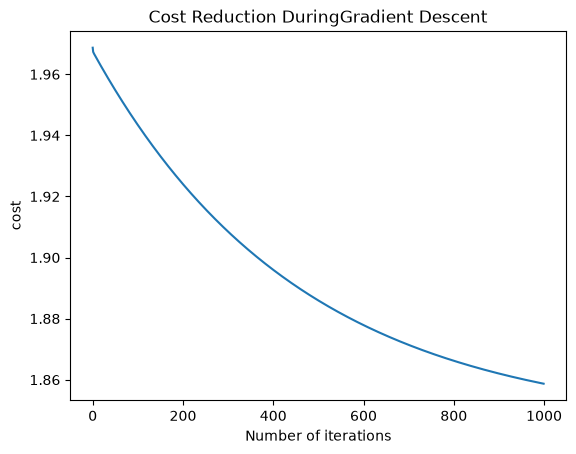

In [ ]:
plt.plot(cost_history)plt.xlabel("Number of iterations")plt.ylabel("cost")plt.title("Cost Reduction During Gradient Descent")plt.show()           

### Initial exploratory evaluation

The following cells show the first evaluation of the G2-only model. This was useful during model development.

**Evaluation note:** the 79-record test subset used here is the same test subset reused later in the model-comparison workflow. Therefore, the later test result should not be described as an entirely untouched, independent holdout result. This is disclosed again in the limitations.

In [ ]:
# lets now evaluate our data on the unseen data (X_test, y_test)

train_cost = cost_function(X_train, y_train, w_final, b_final)
test_cost = cost_function(X_test, y_test, w_final, b_final)

print(train_cost)
print(test_cost)

1.8586992644202167
2.093919818873887


In [ ]:
# Generate predictions for the test set
test_predictions = function_wb(X_test, w_final, b_final)

# Compare the first 10 students
comparison = np.column_stack((
    X_test[:10],
    y_test[:10],
    test_predictions[:10]
))

print("G2 | Actual G3 | Predicted G3")
print(np.round(comparison, 2))

In [ ]:
# Baseline prediction
baseline_prediction = y_train.mean()
baseline_predictions = np.full(y_test.shape, baseline_prediction, dtype = float)

# Linear Regression Predictions
test_predictions = function_wb(X_test, w_final, b_final)

print(baseline_prediction)
print(baseline_predictions[:5])
print(test_predictions[:5])
print(y_test[:5])

10.325949367088608
[10.32594937 10.32594937 10.32594937 10.32594937 10.32594937]
[ 7.54858391 11.8202438   4.34483898  8.61649888  8.61649888]
[10. 12.  5. 10.  9.]


In [ ]:
baseline_mae = np.mean(np.abs(y_test - baseline_predictions))

model_mae = np.mean(np.abs(y_test - test_predictions))

print(baseline_mae)
print(model_mae)

3.64585002403461
1.1457871800154924


In [ ]:
# Lets compare 
train_predictions = function_wb(X_train, w_final, b_final)

train_mae = np.mean(np.abs(y_train - train_predictions))

print(train_mae)
print(model_mae)

1.0876220506020167
1.1457871800154924


## 4. Compare one-feature and two-feature models

We next compare two approaches:

1. A model using `G2` only.
2. A model using both `G1` and `G2`.

For this comparison, the original 80% training portion is divided again into a training subset and a validation subset. The 20% test subset is retained for the final project check.

In [ ]:
X_multi = data[["G1", "G2"]].to_numpy(dtype = float)

print(X_multi.shape)
print("First 5 observations:")
print(X_multi[:5])


(395, 2)
First 5 observations:
[[ 5.  6.]
 [ 5.  5.]
 [ 7.  8.]
 [15. 14.]
 [ 6. 10.]]


In [ ]:
# Split the data into train and test sets
X_multi_train, X_multi_test, y_train_multi, y_test_multi = train_test_split(
    X_multi, y, test_size = 0.2, random_state = 42)

In [ ]:
# then lets separate train and validation test
X_multi_train, X_multi_val, y_train_multi, y_val_multi = train_test_split(
    X_multi_train, y_train_multi, test_size = 0.2, random_state = 42)

In [ ]:
print("Training features:", X_multi_train.shape)
print("Validation features:", X_multi_val.shape)
print("Test features:", X_multi_test.shape)
print("Training targets:", y_train_multi.shape)
print("Validation targets:", y_val_multi.shape)
print("Test targets:", y_test_multi.shape)

Training features: (252, 2)
Validation features: (64, 2)
Test features: (79, 2)
Training targets: (252,)
Validation targets: (64,)
Test targets: (79,)


### Build the two-feature prediction function

With two input features, the model has two weights: one for `G1` and one for `G2`, together with a bias term.

The prediction function is:

\[
\widehat{G3} = w_1G1 + w_2G2 + b
\]

In [ ]:
# Lets create the prediction function for the two input features y_hat = w1G1 + w2G2 + b
def function_wb_multi(X, w, b):
    return np.dot(X, w) + b

# Initialise our parameters w and b
w_multi = np.zeros(X_multi_train.shape[1])
b_multi = 0.0

print(w_multi)
print(b_multi)

[0. 0.]
0.0


In [ ]:
# Test the prediction function before building the cost function
predictions = function_wb_multi(X_multi_train[:5], w_multi, b_multi)

print("First 5 input observations:")
print(X_multi_train[:5])

print("Predictions")
print(predictions)

predictions.shape



First 5 input observations:
[[19. 19.]
 [11. 12.]
 [ 8.  9.]
 [11. 12.]
 [11. 10.]]
Predictions
[0. 0. 0. 0. 0.]


(5,)

### Cost function for the two-feature model

The prediction function produces estimates from `G1` and `G2`. The cost function measures how far those estimates are from the actual `G3` values.

In [ ]:
def cost_function_multi(X, y, w, b):
    m = X.shape[0]

    predictions= function_wb_multi(X, w, b)

    cost = (1/(2 * m)) * np.sum((predictions - y) ** 2)

    return cost

In [ ]:
# Lets test the cost function
initial_cost_multi = cost_function_multi(
    X_multi_train,
    y_train_multi,
    w_multi,
    b_multi
)

print(initial_cost_multi)

67.25992063492063


### Compute gradients for the two-feature model

The model has three parameters to update: the weight for `G1`, the weight for `G2`, and the bias `b`.

A gradient tells us how the cost changes when one of these parameters changes. We calculate the gradients before updating the weights and bias.

In [ ]:
def compute_gradient_multi(X_train, y_train, weights, bias):

    # Number of training examples
    m = X_train.shape[0]

    # Calculate predictions
    predictions = function_wb_multi(X_train, weights, bias)

    # Calculate prediction errors
    errors = predictions - y_train

    # Calculate gradients for the weights
    dj_dw = (1 / m) * np.dot(X_train.T, errors)

    # Calculate gradient for the bias
    dj_db = (1 / m) * np.sum(errors)

    return dj_dw, dj_db

In [ ]:
# lets test the gradient
dj_dw_multi, dj_db_multi = compute_gradient_multi(
    X_multi_train,
    y_train_multi,
    w_multi,
    b_multi
)

print(dj_dw_multi)
print(dj_db_multi)

[-131.23809524 -131.84920635]
-10.59126984126984


In [ ]:
# computing gradient descent update for one
# lets set our alpha (learning rate) to 0.001
alpha = 0.001

# w1 and w2 update
w_test = w_multi - alpha * dj_dw_multi

# Update the bias
b_test = b_multi - alpha * dj_db_multi

print(w_test)
print(b_test)

[0.1312381  0.13184921]
0.01059126984126984


In [ ]:
# Now lets compute the cost again after computing gradient descent update
cost_after_one_step = cost_function_multi(
    X_multi_train,
    y_train_multi,
    w_test,
    b_test
)

print(initial_cost_multi)
print(cost_after_one_step)

67.25992063492063
37.20487166004479


### Implement and train gradient descent for two features

The gradient descent function below automates the repeated prediction, gradient calculation, parameter update and cost recording steps.

In [ ]:
# Now lets create gradient descent function that will automate the process of calculating 
# the prediction, error, gradient, update the weights and bias (w1, w2, b), and then calculate the new cost

def gradient_descent_multi(X_train, y_train, w_init, b_init, alpha, num_iters):
    # copy the initial parameters
    w = w_init.copy()
    b = b_init

    # Create an empty list to store the cost values
    cost_history = []

    # Repeat the learning process
    for i in range(num_iters):
        # Calculate gradients
        dj_dw, dj_db = compute_gradient_multi(X_train, y_train, w, b)

        # Update weights and bias
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Calculate cost after update
        cost = cost_function_multi(X_train, y_train, w, b)

        # store the resultant cost
        cost_history.append(cost)

        # we want the cost for every 100 iteration displayed
        if (i + 1) % 100 == 0:
            print(f"Iteration {i + 1}: cost = {cost:.6f}")
            
    return w, b, cost_history
        
        

In [ ]:
# Lets call the function
w_multi_final, b_multi_final, cost_history_multi = gradient_descent_multi(
    X_multi_train, y_train_multi, w_multi, b_multi, alpha = 0.001, num_iters = 1000)


Iteration 100: cost = 2.467877
Iteration 200: cost = 2.342010
Iteration 300: cost = 2.260990
Iteration 400: cost = 2.208515
Iteration 500: cost = 2.174214
Iteration 600: cost = 2.151489
Iteration 700: cost = 2.136142
Iteration 800: cost = 2.125504
Iteration 900: cost = 2.117874
Iteration 1000: cost = 2.112173


In [ ]:
print("Trained weights:", w_multi_final)
print("Trained bias:", b_multi_final)

print("Initial cost:", initial_cost_multi)
print("Cost after first iteration:", cost_history_multi[0])
print("Final training cost:", cost_history_multi[-1])

print("Number of iterations:", len(cost_history_multi))

Trained weights: [0.07625117 0.92404197]
Trained bias: -0.15766255133627508
Initial cost: 67.25992063492063
Cost after first iteration: 37.20487166004479
Final training cost: 2.1121726674649075
Number of iterations: 1000


### Evaluate the G1 + G2 model on validation data

We generate predictions for the validation subset and calculate Mean Absolute Error (MAE). MAE is the average absolute difference between predicted and actual grades.

In [ ]:
# Generate predictions using validation features
val_predictions_multi = function_wb_multi(
    X_multi_val,
    w_multi_final,
    b_multi_final
)

print("First 5 validation predictions:")
print(val_predictions_multi[:5])

print("First 5 actual grades:")
print(y_val_multi[:5])

First 5 validation predictions:
[ 8.69247343 10.7693109  10.92181325  8.84497578  8.99747813]
First 5 actual grades:
[ 8. 11. 11. 10.  9.]


In [ ]:
# Step 1: Calculate prediction errors
val_errors_multi = val_predictions_multi - y_val_multi

# Step 2: Convert errors to absolute values
val_absolute_errors_multi = np.abs(val_errors_multi)

# Step 3: Calculate the average absolute error
val_mae_multi = np.mean(val_absolute_errors_multi)

# Display the result
print("Validation MAE:", val_mae_multi)

Validation MAE: 0.9142916357965285


### Train and evaluate the G2-only comparison model

To make a fair validation comparison, we train a second model using only `G2`, with the same training and validation observations used for the two-feature model.

In [ ]:
# Extract G2 from the training data
X_g2_train = X_multi_train[:, 1:2]

# Extract G2 from the validation data
X_g2_val = X_multi_val[:, 1:2]

# Check the shapes
print("G2 training shape:", X_g2_train.shape)
print("G2 validation shape:", X_g2_val.shape)

## Model comparison

### Initialise and train the G2-only model

In [ ]:
# Initialise the parameters
w_g2_init = np.zeros(X_g2_train.shape[1])
b_g2_init = 0.0

print("Initial weight:", w_g2_init)
print("Initial bias:", b_g2_init)

Initial weight: [0.]
Initial bias: 0.0


In [ ]:
# Train the G2 only model
w_g2_final, b_g2_final, cost_history_g2 = gradient_descent_multi(
    X_g2_train,
    y_train_multi,
    w_g2_init,
    b_g2_init,
    alpha=0.001,
    num_iters=1000
)

Iteration 100: cost = 2.143545
Iteration 200: cost = 2.140739
Iteration 300: cost = 2.137994
Iteration 400: cost = 2.135309
Iteration 500: cost = 2.132684
Iteration 600: cost = 2.130117
Iteration 700: cost = 2.127606
Iteration 800: cost = 2.125151
Iteration 900: cost = 2.122750
Iteration 1000: cost = 2.120402


In [ ]:
# Inspect the trained model
print("G2-only weight:", w_g2_final)
print("G2-only bias:", b_g2_final)
print("Final training cost:", cost_history_g2[-1])

G2-only weight: [0.99437769]
G2-only bias: -0.08057916479129552
Final training cost: 2.1204017747728034


## Calculate the G2-only validation MAE

In [ ]:
# Generate predictions using G2-only model
val_predictions_g2 = function_wb_multi(
    X_g2_val,
    w_g2_final,
    b_g2_final
)

# Calculate prediction errors
val_errors_g2 = val_predictions_g2 - y_val_multi

# Convert errors to absolute values
val_absolute_errors_g2 = np.abs(val_errors_g2)

# Calculate validation MAE
val_mae_g2 = np.mean(val_absolute_errors_g2)

print("G2-only validation MAE:", val_mae_g2)

G2-only validation MAE: 0.8762928269564461


### Select the model using validation MAE

| Model | Validation MAE |
|---|---:|
| G1 + G2 | 0.9143 |
| G2 only | 0.8763 |

The G2-only model has the slightly lower validation MAE. We therefore select it as the final model for this project. The difference is small and comes from this particular validation split; it does not prove that `G1` has no predictive value.

## 5. Final evaluation on the test subset

We now evaluate the selected G2-only model on the 79-record test subset.

### Extract G2 from the test data

In [ ]:
# Extract G2 from the test data
X_g2_test = X_multi_test[:, 1:2]

print("Test features shape:", X_g2_test.shape)

Test features shape: (79, 1)


In [ ]:
# Generate predictions and calculate MAE
# Generate test predictions
test_predictions_g2 = function_wb_multi(
    X_g2_test,
    w_g2_final,
    b_g2_final
)

# Calculate absolute prediction errors
test_errors_g2 = np.abs(test_predictions_g2 - y_test_multi)

# Calculate test MAE
test_mae_g2 = np.mean(test_errors_g2)

print("Final test MAE:", test_mae_g2)

Final test MAE: 1.0877938850176425


### Compare the selected model with a mean baseline

In [ ]:
baseline_prediction = np.mean(y_train_multi)

baseline_test_predictions = np.full_like(
    y_test_multi,
    baseline_prediction,
    dtype=float
)

baseline_test_mae = np.mean(
    np.abs(baseline_test_predictions - y_test_multi)
)

print("Baseline test MAE:", baseline_test_mae)

Baseline test MAE: 3.635774562989753


### Final test results

| Model | Test MAE |
|---|---:|
| Mean baseline | 3.6358 |
| Selected G2-only linear regression | 1.0878 |

The selected model's test MAE is approximately **70.1% lower** than the mean baseline's test MAE.

The baseline always predicts the average `G3` value from the training data. The linear regression model uses each student's `G2` value to make an individual prediction.

**Interpretation caution:** this test subset was examined during the earlier exploratory G2-only evaluation. The final test MAE is useful as a project check, but it should not be presented as an unbiased result from a completely untouched test set.

## 6. Use the trained model to make a prediction

The selected model uses the trained G2-only weight and bias:

\[
\widehat{G3} = 0.99437769(G2) - 0.08057916
\]

The function below uses the full-precision values stored in `w_g2_final` and `b_g2_final`, rather than rounded coefficients.

In [ ]:
# 
def predict_g3(g2):
    prediction = w_g2_final[0] * g2 + b_g2_final
    return prediction

In [ ]:
predicted_grade = predict_g3(12)

print("Predicted G3:", predicted_grade)

Predicted G3: 11.8519530601115


## 7. Conclusion and limitations

### Conclusion

This project implemented linear regression manually using NumPy. It covered the prediction function, cost function, gradient calculations, gradient descent, validation-based model comparison and test evaluation.

The G2-only model was selected because it achieved a slightly lower validation MAE than the G1 + G2 model:

- G2-only validation MAE: **0.8763**
- G1 + G2 validation MAE: **0.9143**
- Selected model test MAE: **1.0878**
- Mean baseline test MAE: **3.6358**

For a student with `G2 = 12`, the trained model predicts a `G3` value of approximately **11.85**.

### Limitations

1. The model was developed using one dataset. Its performance should not be assumed to generalise to students from other schools or populations without further testing.
2. The model uses `G2` as its only input, so it does not account for other factors that may influence final grades.
3. The test subset was examined during an earlier exploratory stage and reused later. The reported test result is therefore not an independent, untouched holdout estimate.
4. Predictions are estimates, not guarantees. They should not replace teachers' judgement or be used as the sole basis for decisions about individual students.